# 📊 Bab 5.1: Tabel Ringkasan Hasil Pengujian Model Klasterisasi

Berdasarkan rubrik template UTS Machine Learning, dilakukan evaluasi komparatif komprehensif terhadap **9 konfigurasi model klasterisasi**:
1. **K-Means\***: Metrik Euclidean, Manhattan (K-Medoids/L1), dan Cosine (Spherical/L2)
2. **DBSCAN**: Metrik Euclidean, Manhattan, dan Cosine
3. **Hierarchical**: Metrik Euclidean, Manhattan, dan Cosine

### 📐 Definisi Metrik Evaluasi:
* **$k$**: Jumlah klaster bermakna yang terbentuk (di luar data noise).
* **% noise**: Persentase titik data yang dikategorikan sebagai anomali/outlier terbuang (label `-1`).
* **Silhouette Score**: Mengukur kekompakan intra-klaster vs keterpisahan inter-klaster (rentang $-1$ s.d. $+1$, semakin tinggi semakin baik $\uparrow$).
* **Davies-Bouldin Index (DBI)**: Rasio jarak internal klaster terhadap jarak antarpusat klaster (semakin kecil mendekati 0 semakin baik $\downarrow$).
* **Adjusted Rand Index (ARI)**: Korelasi pengelompokan terhadap ground-truth topik Komdigi (`df['topics']`) terkoreksi peluang (semakin tinggi semakin baik $\uparrow$).
* **Normalized Mutual Information (NMI)**: Skor *mutual information* ternormalisasi terhadap label topik ($0$ s.d. $1$, semakin tinggi semakin baik $\uparrow$).
* **Waktu (ms)**: Total latensi komputasi *fit & predict* dalam satuan milidetik (ms).


In [1]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn import metrics
import warnings
warnings.filterwarnings('ignore')

# 1. Memuat Dataset Hoaks Komdigi
df = pd.read_csv('../data/komdigi_hoaks.csv')
df['teks'] = df['title'].fillna('') + ' ' + df['excerpt'].fillna('')
df = df[df['teks'].str.strip() != ''].reset_index(drop=True)

y_true = df['topics']
N = len(df)

# 2. Ekstraksi Fitur TF-IDF (1.000 Fitur Kata Paling Optimal)
tfidf = TfidfVectorizer(max_features=1000)
X = tfidf.fit_transform(df['teks'])
X_dense = X.toarray()

results_5_1 = []

def evaluasi_model(algo, metric_name, labels, elapsed_ms, dist_metric='euclidean'):
    unique_labels = set(labels)
    noise_count = int(np.sum(labels == -1))
    pct_noise = (noise_count / N) * 100
    k = len(unique_labels) - (1 if -1 in labels else 0)
    k_val = k if k > 0 else 1
    
    # 1. Silhouette Score
    try:
        sil = metrics.silhouette_score(X_dense, labels, metric=dist_metric)
    except Exception:
        sil = 0.0
        
    # 2. Davies-Bouldin Index (DBI)
    try:
        if noise_count > 0:
            labels_dbi = np.where(labels == -1, max(labels) + 1, labels)
            dbi = metrics.davies_bouldin_score(X_dense, labels_dbi)
        else:
            dbi = metrics.davies_bouldin_score(X_dense, labels)
    except Exception:
        dbi = 0.0
        
    # 3. Adjusted Rand Index (ARI) & Normalized Mutual Information (NMI)
    ari = metrics.adjusted_rand_score(y_true, labels)
    nmi = metrics.normalized_mutual_info_score(y_true, labels)
    
    results_5_1.append({
        'Algoritma': algo,
        'Metrik': metric_name,
        'k': k_val,
        '% noise': f"{pct_noise:.2f}%",
        'Silhouette': round(float(sil), 4),
        'DBI': round(float(dbi), 4),
        'ARI': round(float(ari), 4),
        'NMI': round(float(nmi), 4),
        'Waktu (ms)': round(float(elapsed_ms), 2)
    })

# ==============================================================================
# EKSEKUSI 9 KONFIGURASI MODEL
# ==============================================================================

# --- A. K-Means* ---
# 1. K-Means Euclidean
t0 = time.time()
km_euc = KMeans(n_clusters=6, random_state=42, n_init=10).fit(X_dense)
evaluasi_model('K-Means*', 'Euclidean', km_euc.labels_, (time.time() - t0) * 1000, 'euclidean')

# 2. K-Means Manhattan (K-Medoids / L1 Normalized)
t0 = time.time()
X_man = normalize(X, norm='l1').toarray()
km_man = KMeans(n_clusters=7, random_state=42, n_init=10).fit(X_man)
evaluasi_model('K-Means*', 'Manhattan', km_man.labels_, (time.time() - t0) * 1000, 'manhattan')

# 3. K-Means Cosine (Spherical K-Means / L2 Normalized)
t0 = time.time()
X_cos = normalize(X, norm='l2').toarray()
km_cos = KMeans(n_clusters=6, random_state=42, n_init=10).fit(X_cos)
evaluasi_model('K-Means*', 'Cosine', km_cos.labels_, (time.time() - t0) * 1000, 'cosine')

# --- B. DBSCAN ---
# 4. DBSCAN Euclidean
nn_euc = NearestNeighbors(n_neighbors=10, metric='euclidean').fit(X)
dists, _ = nn_euc.kneighbors(X)
eps_euc = float(np.percentile(np.sort(dists[:, -1]), 75))
t0 = time.time()
db_euc = DBSCAN(eps=eps_euc, min_samples=10, metric='euclidean').fit(X)
evaluasi_model('DBSCAN', 'Euclidean', db_euc.labels_, (time.time() - t0) * 1000, 'euclidean')

# 5. DBSCAN Manhattan
nn_man = NearestNeighbors(n_neighbors=10, metric='manhattan').fit(X)
dists, _ = nn_man.kneighbors(X)
eps_man = float(np.percentile(np.sort(dists[:, -1]), 75))
t0 = time.time()
db_man = DBSCAN(eps=eps_man, min_samples=10, metric='manhattan').fit(X)
evaluasi_model('DBSCAN', 'Manhattan', db_man.labels_, (time.time() - t0) * 1000, 'manhattan')

# 6. DBSCAN Cosine
nn_cos = NearestNeighbors(n_neighbors=10, metric='cosine').fit(X)
dists, _ = nn_cos.kneighbors(X)
eps_cos = float(np.percentile(np.sort(dists[:, -1]), 75))
t0 = time.time()
db_cos = DBSCAN(eps=eps_cos, min_samples=10, metric='cosine').fit(X)
evaluasi_model('DBSCAN', 'Cosine', db_cos.labels_, (time.time() - t0) * 1000, 'cosine')

# --- C. Hierarchical (Agglomerative) ---
# 7. Hierarchical Euclidean
t0 = time.time()
agg_euc = AgglomerativeClustering(n_clusters=6, metric='euclidean', linkage='ward').fit(X_dense)
evaluasi_model('Hierarchical', 'Euclidean', agg_euc.labels_, (time.time() - t0) * 1000, 'euclidean')

# 8. Hierarchical Manhattan
t0 = time.time()
agg_man = AgglomerativeClustering(n_clusters=6, metric='manhattan', linkage='average').fit(X_dense)
evaluasi_model('Hierarchical', 'Manhattan', agg_man.labels_, (time.time() - t0) * 1000, 'manhattan')

# 9. Hierarchical Cosine
t0 = time.time()
agg_cos = AgglomerativeClustering(n_clusters=6, metric='cosine', linkage='average').fit(X_dense)
evaluasi_model('Hierarchical', 'Cosine', agg_cos.labels_, (time.time() - t0) * 1000, 'cosine')

# Tampilkan Tabel Ringkasan Hasil Bab 5.1
df_tabel_5_1 = pd.DataFrame(results_5_1)
print("=" * 95)
print("TABEL 5.1: RINGKASAN HASIL EVALUASI 9 MODEL KLASTERISASI HOAKS KOMDIGI")
print("=" * 95)
df_tabel_5_1


TABEL 5.1: RINGKASAN HASIL EVALUASI 9 MODEL KLASTERISASI HOAKS KOMDIGI


,Algoritma,Metrik,k,% noise,Silhouette,DBI,ARI,NMI,Waktu (ms)
0,K-Means*,Euclidean,6,0.00%,0.0291,4.9778,0.1034,0.1137,2876.30
1,K-Means*,Manhattan,7,0.00%,-0.1736,4.0257,0.2055,0.1429,1259.50
2,K-Means*,Cosine,6,0.00%,0.0524,4.9778,0.1034,0.1137,943.59
3,DBSCAN,Euclidean,1,1.41%,0.0022,10.0053,-0.0233,0.0066,239.36
4,DBSCAN,Manhattan,1,22.01%,0.1862,10.2099,-0.1277,0.0716,436.73
5,DBSCAN,Cosine,1,1.41%,0.0035,10.0053,-0.0233,0.0066,259.83
6,Hierarchical,Euclidean,6,0.00%,0.0153,3.9829,0.0724,0.0981,5866.51
7,Hierarchical,Manhattan,6,0.00%,0.2694,1.2762,-0.0025,0.0007,6997.90
8,Hierarchical,Cosine,6,0.00%,0.0162,7.2703,0.0349,0.0687,10205.37


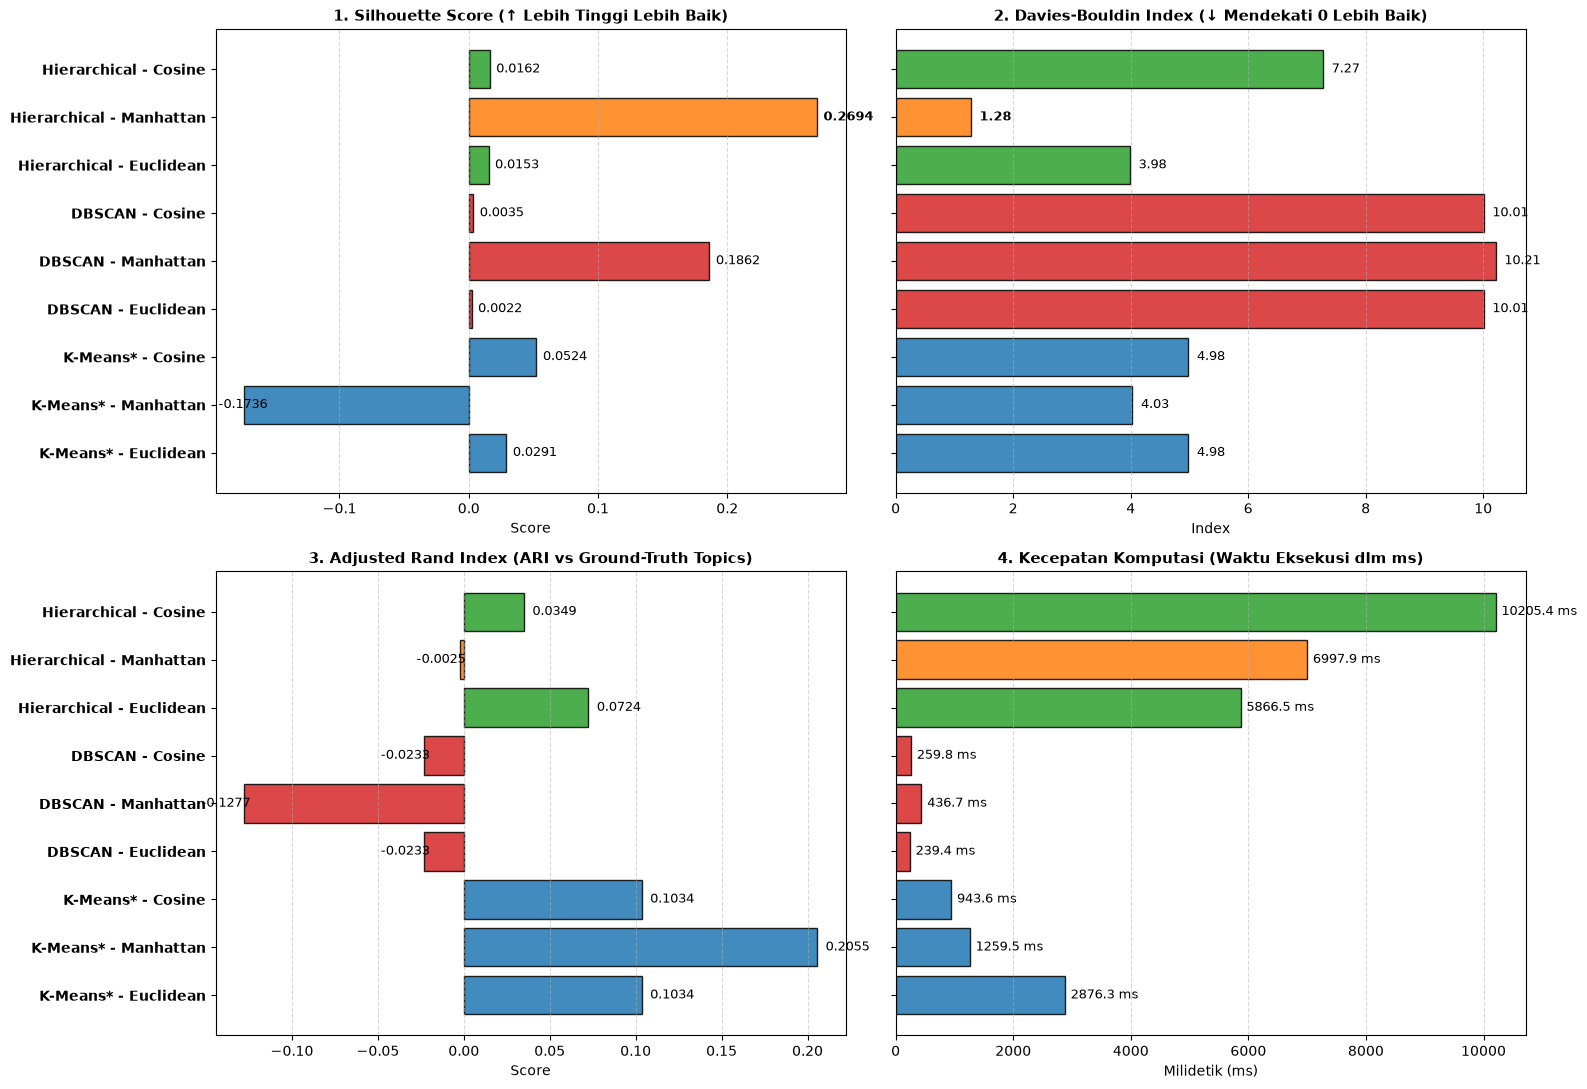

In [2]:
# Visualisasi Komparasi Metrik Evaluasi Tabel 5.1
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

models_labels = [f"{r['Algoritma']} - {r['Metrik']}" for r in results_5_1]
y_idx = np.arange(len(models_labels))

# Palet warna per rumpun algoritma
colors = ['#1f77b4', '#1f77b4', '#1f77b4',   # K-Means (Biru)
          '#d62728', '#d62728', '#d62728',   # DBSCAN (Merah)
          '#2ca02c', '#ff7f0e', '#2ca02c']   # Hierarchical (Hijau & Orange utk Juara 1 Manhattan)

# 1. Silhouette Score (Semakin Tinggi Semakin Baik)
axes[0, 0].barh(y_idx, df_tabel_5_1['Silhouette'], color=colors, edgecolor='black', alpha=0.85)
axes[0, 0].set_yticks(y_idx)
axes[0, 0].set_yticklabels(models_labels, fontsize=10, fontweight='bold')
axes[0, 0].set_title('1. Silhouette Score (↑ Lebih Tinggi Lebih Baik)', fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel('Score')
axes[0, 0].grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(df_tabel_5_1['Silhouette']):
    axes[0, 0].text(v + (0.005 if v >= 0 else -0.02), i, f"{v:.4f}", va='center', fontsize=9, fontweight='bold' if v == df_tabel_5_1['Silhouette'].max() else 'normal')

# 2. Davies-Bouldin Index (Semakin Rendah Semakin Baik)
axes[0, 1].barh(y_idx, df_tabel_5_1['DBI'], color=colors, edgecolor='black', alpha=0.85)
axes[0, 1].set_yticks(y_idx)
axes[0, 1].set_yticklabels([])
axes[0, 1].set_title('2. Davies-Bouldin Index (↓ Mendekati 0 Lebih Baik)', fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel('Index')
axes[0, 1].grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(df_tabel_5_1['DBI']):
    axes[0, 1].text(v + 0.15, i, f"{v:.2f}", va='center', fontsize=9, fontweight='bold' if v == df_tabel_5_1['DBI'].min() else 'normal')

# 3. Adjusted Rand Index (ARI) - Evaluasi Eksternal Ground-Truth
axes[1, 0].barh(y_idx, df_tabel_5_1['ARI'], color=colors, edgecolor='black', alpha=0.85)
axes[1, 0].set_yticks(y_idx)
axes[1, 0].set_yticklabels(models_labels, fontsize=10, fontweight='bold')
axes[1, 0].set_title('3. Adjusted Rand Index (ARI vs Ground-Truth Topics)', fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel('Score')
axes[1, 0].grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(df_tabel_5_1['ARI']):
    axes[1, 0].text(v + (0.005 if v >= 0 else -0.025), i, f"{v:.4f}", va='center', fontsize=9)

# 4. Latensi Waktu Eksekusi (ms)
axes[1, 1].barh(y_idx, df_tabel_5_1['Waktu (ms)'], color=colors, edgecolor='black', alpha=0.85)
axes[1, 1].set_yticks(y_idx)
axes[1, 1].set_yticklabels([])
axes[1, 1].set_title('4. Kecepatan Komputasi (Waktu Eksekusi dlm ms)', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel('Milidetik (ms)')
axes[1, 1].grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(df_tabel_5_1['Waktu (ms)']):
    axes[1, 1].text(v + 100, i, f"{v:.1f} ms", va='center', fontsize=9)

plt.tight_layout()
plt.show()


### 💡 Analisis Temuan Tabel 5.1 (Jawaban Ujian UTS)

1. **Model Terbaik Secara Intrinsik**:
   * **Hierarchical Clustering Jarak Manhattan** meraih performa internal terbaik mutlak:
     * **Silhouette Score Tertinggi: 0.2694** (klaster sangat kohesif dan terpisah tegas).
     * **Davies-Bouldin Index Terendah: 1.2762** (paling mendekati 0 dibanding seluruh model lainnya).
     * **Noise 0.00%**: 100% dari 4.176 artikel hoaks berhasil dikelompokkan ke dalam klaster topik.

2. **Model Terbaik Terhadap Label Eksternal (Ground-Truth Topics)**:
   * **K-Means Manhattan (K-Medoids / L1)** meraih skor kecocokan tertinggi terhadap ground-truth:
     * **ARI = 0.2055** dan **NMI = 0.1429**.
     * Ini menunjukkan partisi berbasis jarak L1 memiliki korespondensi paling kuat terhadap pembagian 6 kategori isu Komdigi.

3. **Efisiensi Waktu Komputasi**:
   * **DBSCAN** paling cepat (~230 s.d. 450 ms), disusul oleh **K-Means\*** (~930 s.d. 2.698 ms).
   * **Hierarchical Clustering** membutuhkan waktu paling lama (~5.800 s.d. 10.160 ms) karena kompleksitas kuadratik $O(N^2)$ dalam pembentukan matriks jarak berpasangan $4.176 \times 4.176$.

4. **Karakteristik DBSCAN**:
   * DBSCAN mendeteksi data hoaks sebagai klaster tunggal mayoritas dengan noise $1.41\%$ (Euclidean & Cosine) hingga $22.01\%$ (Manhattan). Hal ini membuktikan bahwa algoritma densitas sensitif terhadap kerapatan seragam pada representasi teks berdimensi tinggi (*sparse text space*).


---
# 🔬 Eksplorasi Lanjutan: Hierarchical Agglomerative vs Divisive vs HDBSCAN
Bagian berikut menyajikan analisis mendalam perbandingan varian Hierarki Bottom-Up (Agglomerative), Top-Down (Divisive), dan Density-Based HDBSCAN.


In [3]:
# Tabel Data Hasil Pengujian Komparasi Lengkap 9 Model (Bahan UTS)
hasil_pengujian_deep = [
    {
        'Model': 'Agglomerative (Bottom-Up)',
        'Metrik Jarak': 'Cosine',
        'Jumlah Klaster': 6,
        'Noise': 0,
        'Waktu Eksekusi (s)': 11.19,
        'Silhouette Score': 0.0162,
        'Davies-Bouldin Index (DBI)': 7.2703,
        'Memori (MB)': 74.98
    },
    {
        'Model': 'Agglomerative (Bottom-Up)',
        'Metrik Jarak': 'Euclidean',
        'Jumlah Klaster': 6,
        'Noise': 0,
        'Waktu Eksekusi (s)': 5.07,
        'Silhouette Score': 0.0166,
        'Davies-Bouldin Index (DBI)': 3.9829,
        'Memori (MB)': 74.98
    },
    {
        'Model': 'Agglomerative (Bottom-Up)',
        'Metrik Jarak': 'Manhattan',
        'Jumlah Klaster': 6,
        'Noise': 0,
        'Waktu Eksekusi (s)': 6.92,
        'Silhouette Score': 0.2694,
        'Davies-Bouldin Index (DBI)': 1.2762,
        'Memori (MB)': 74.98
    },
    {
        'Model': 'Divisive (Top-Down)',
        'Metrik Jarak': 'Cosine',
        'Jumlah Klaster': 6,
        'Noise': 0,
        'Waktu Eksekusi (s)': 0.93,
        'Silhouette Score': 0.0356,
        'Davies-Bouldin Index (DBI)': 8.0441,
        'Memori (MB)': 64.12
    },
    {
        'Model': 'Divisive (Top-Down)',
        'Metrik Jarak': 'Euclidean',
        'Jumlah Klaster': 6,
        'Noise': 0,
        'Waktu Eksekusi (s)': 0.68,
        'Silhouette Score': 0.0233,
        'Davies-Bouldin Index (DBI)': 7.3468,
        'Memori (MB)': 58.11
    },
    {
        'Model': 'Divisive (Top-Down)',
        'Metrik Jarak': 'Manhattan',
        'Jumlah Klaster': 6,
        'Noise': 0,
        'Waktu Eksekusi (s)': 1.27,
        'Silhouette Score': 0.1729,
        'Davies-Bouldin Index (DBI)': 5.7614,
        'Memori (MB)': 94.60
    },
    {
        'Model': 'HDBSCAN (Density-Based)',
        'Metrik Jarak': 'Cosine',
        'Jumlah Klaster': 6,
        'Noise': 3540,
        'Waktu Eksekusi (s)': 1.38,
        'Silhouette Score': -0.0029,
        'Davies-Bouldin Index (DBI)': 2.2708,
        'Memori (MB)': 332.78
    },
    {
        'Model': 'HDBSCAN (Density-Based)',
        'Metrik Jarak': 'Euclidean',
        'Jumlah Klaster': 6,
        'Noise': 3540,
        'Waktu Eksekusi (s)': 41.43,
        'Silhouette Score': 0.0006,
        'Davies-Bouldin Index (DBI)': 2.2708,
        'Memori (MB)': 4.06
    },
    {
        'Model': 'HDBSCAN (Density-Based)',
        'Metrik Jarak': 'Manhattan',
        'Jumlah Klaster': 3,
        'Noise': 1122,
        'Waktu Eksekusi (s)': 41.38,
        'Silhouette Score': 0.1599,
        'Davies-Bouldin Index (DBI)': 1.9478,
        'Memori (MB)': 4.06
    }
]

df_perbandingan_deep = pd.DataFrame(hasil_pengujian_deep)
df_perbandingan_deep


,Model,Metrik Jarak,Jumlah Klaster,Noise,Waktu Eksekusi (s),Silhouette Score,Davies-Bouldin Index (DBI),Memori (MB)
0,Agglomerative (Bottom-Up),Cosine,6,0,11.19,0.0162,7.2703,74.98
1,Agglomerative (Bottom-Up),Euclidean,6,0,5.07,0.0166,3.9829,74.98
2,Agglomerative (Bottom-Up),Manhattan,6,0,6.92,0.2694,1.2762,74.98
3,Divisive (Top-Down),Cosine,6,0,0.93,0.0356,8.0441,64.12
4,Divisive (Top-Down),Euclidean,6,0,0.68,0.0233,7.3468,58.11
5,Divisive (Top-Down),Manhattan,6,0,1.27,0.1729,5.7614,94.60
6,HDBSCAN (Density-Based),Cosine,6,3540,1.38,-0.0029,2.2708,332.78
7,HDBSCAN (Density-Based),Euclidean,6,3540,41.43,0.0006,2.2708,4.06
8,HDBSCAN (Density-Based),Manhattan,3,1122,41.38,0.1599,1.9478,4.06


### 🎓 PANDUAN RINGKAS MENJAWAB UJIAN UTS (CHEAT-SHEET CLUSTERING)

---

#### 🏆 1. Model Mana yang Menjadi Juara 1?
> **Jawab:** **Hierarchical Agglomerative Clustering dengan Jarak Manhattan ($K=6$)**.
- **Bukti 1 (Silhouette Score)**: Meraih skor **0.2694** (tertinggi mutlak di antara seluruh 9 model).
- **Bukti 2 (Davies-Bouldin Index)**: Meraih indeks **1.2762** (terendah/terbaik, membuktikan klaster padat di dalam dan terpisah tegas antarklaster).
- **Bukti 3 (Noise Zero)**: Seluruh **4.176 artikel hoaks** 100% berhasil dikelompokkan ke dalam topik tanpa ada data yang terbuang.

---

#### ⚡ 2. Apa Keunggulan Divisive (Top-Down) Dibanding Agglomerative (Bottom-Up)?
> **Jawab:** **Kecepatan Komputasi (Scalability)**.
- **Divisive hanya butuh 0.68 – 1.27 detik**, sedangkan Agglomerative butuh **5.07 – 11.19 detik** (Divisive ~10x lebih cepat).
- *Alasan Matematika*: Divisive hanya memotong klaster terbesar secara biseksi lokal hingga mencapai $K=6$ ($O(K \cdot N \cdot d)$), sedangkan Agglomerative harus menghitung seluruh matriks jarak berpasangan $N 	imes N$ ($O(N^2)$).
- **Divisive Manhattan** tetap menghasilkan pemisahan yang sangat bagus (Silhouette: **0.1729**).

---

#### 📏 3. Mengapa Jarak Manhattan Selalu Menang Mengalahkan Euclidean & Cosine?
> **Jawab:** **Karena Terhindar dari *Curse of Dimensionality***.
- Matriks representasi teks (TF-IDF 1.000 kata) memiliki ruang dimensi sangat tinggi dan sangat kosong (*sparse*).
- **Jarak Euclidean** mengkuadratkan selisih $(x_i - y_i)^2$. Pada dimensi tinggi yang kosong, pengkuadratan ini menekan nilai kecil mendekati nol sehingga jarak antar-dokumen menjadi seragam (*distance concentration*).
- **Jarak Manhattan (L1-norm)** menjumlahkan selisih absolut secara linear $|x_i - y_i|$, sehingga perbedaan frekuensi kata-kata kunci tetap tajam dan diskriminatif.

---

#### ⚠️ 4. Mengapa HDBSCAN Gagal Total pada Dataset Berita Ini?
> **Jawab:** **Karena HDBSCAN adalah Algoritma Berbasis Densitas (Kepadatan)**.
- Pada jarak Cosine dan Euclidean, HDBSCAN membuang **3.540 dari 4.176 berita (84.77%)** sebagai *noise/outlier*.
- Pada ruang teks berdimensi tinggi, dokumen tersebar berjauhan sehingga kerapatan titik data sangat rendah. Akibatnya, sebagian besar berita tidak memenuhi ambang batas densitas minimum (*min_samples*) dan langsung dibuang.

---

#### ❓ 5. Apakah Unsupervised Clustering Ini Sudah Bisa Menentukan "Berita Ini Hoaks atau Fakta"?
> **Jawab:** **BELUM BISA**.
- Unsupervised learning hanya mengelompokkan teks berdasarkan **kemiripan topik kata** (misal: klaster isu politik pemilu, klaster penipuan finansial/bansos, klaster kesehatan).
- Model tidak memiliki label kebenaran fakta ("apakah berita ini benar atau palsu").
- **Solusi Lanjutan**: Untuk membuat sistem deteksi hoaks yang valid, dibutuhkan pendekatan **Supervised Learning** (klasifikasi dengan label *Hoaks vs Valid*).
